In [1]:
import pandas as pd
from pathlib import Path
from sklearn.preprocessing import StandardScaler

base = Path("../data/processed")
props = pd.read_csv("../data/processed/props_clean.csv")
segs = pd.read_csv("../data/processed/client_segments.csv")

In [2]:
sold = props[props["listing_status"] == "Sold"].copy()
sold["price_per_sqft"] = sold["sale_price"] / sold["floor_area_sqft"]
sold["is_office"] = (sold["unit_category"] == "Office").astype(int)

feat = sold.groupby("client_ref").agg(
    n_purchase=("listing_id","count"),
    avg_price=("sale_price","mean"),
    avg_price_per_sqft=("price_per_sqft","mean"),
    pct_office=("is_office","mean"),
)
feat = feat.loc[segs["client_ref"]]
X = StandardScaler().fit_transform(feat)
print(X.shape)

(2000, 4)


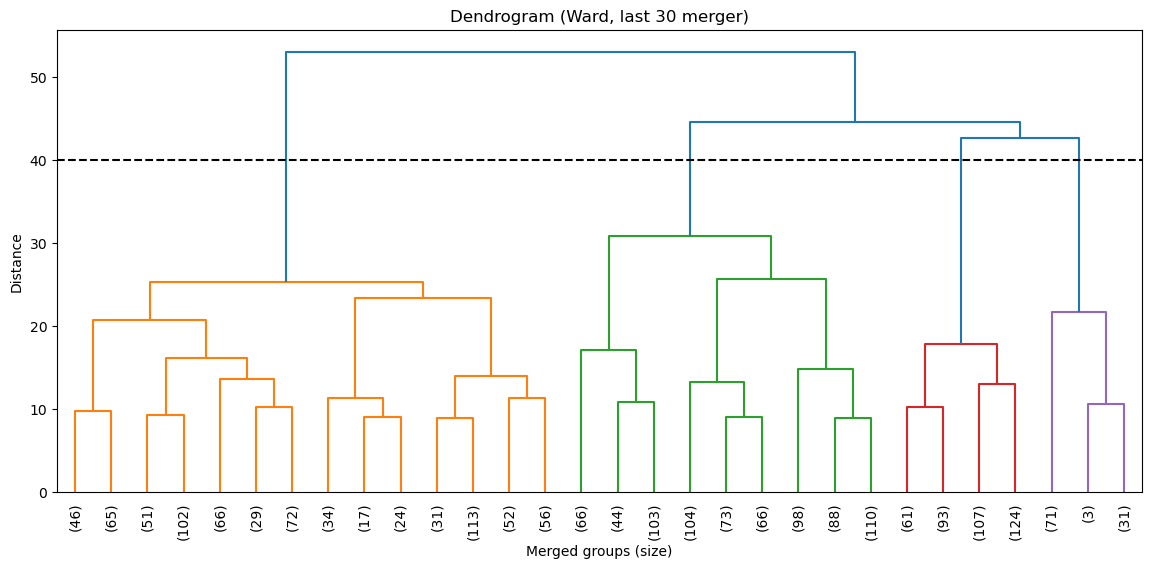

In [3]:
# hierarchical clustering 
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram

Z = linkage(X, method="ward")

plt.figure(figsize=(14,6))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90)
plt.title("Dendrogram (Ward, last 30 merger)")
plt.xlabel("Merged groups (size)")
plt.ylabel("Distance")
plt.axhline(y=40, color="black", linestyle="--")
plt.show()

In [4]:
# cutting the tree at 4 clusters and then comparing with K-means
from scipy.cluster.hierarchy import fcluster
from sklearn.metrics import adjusted_rand_score, silhouette_score

hier = fcluster(Z, t=4, criterion="maxclust")

print("Hierarchical sizes:", pd.Series(hier).value_counts().sort_index().tolist())
print("Silhouette (hier):", round(silhouette_score(X, hier), 3))
print("Agreement with K-means (ARI):", round(adjusted_rand_score(segs["cluster"], hier),3))

print(pd.crosstab(segs["segment"], hier))

Hierarchical sizes: [758, 752, 385, 105]
Silhouette (hier): 0.195
Agreement with K-means (ARI): 0.471
col_0                         1    2    3   4
segment                                      
Budget Buyers               230   75  354  35
Mixed-use Buyers            528   85    0   8
Portfolio Investors           0    0    0  50
Residential Premium Buyers    0  592   31  12
